In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv("/content/ecommerce_unclean.csv")

In [5]:
df.head()

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct
0,EC1001,2026-09-01,South,Laptop,2.0,52000,0.10
1,EC1002,2026-09-02,West,Wireless Mouse,5.0,750,0.05
2,EC1003,2026-09-03,North,Keyboard,3.0,1800,0.00
3,EC1004,2026-09-04,East,Monitor,2.0,14500,0.10
4,EC1005,2026-09-05,South,Headphones,4.0,3200,0.15


In [7]:
print("Shape:" ,df.shape)

Shape: (25, 7)


In [8]:
print("Column name:",df.columns)

Column name: Index(['OrderID', 'Date', 'Region', 'Product', 'Units', 'UnitPrice',
       'DiscountPct'],
      dtype='object')


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   OrderID      25 non-null     object 
 1   Date         25 non-null     object 
 2   Region       24 non-null     object 
 3   Product      24 non-null     object 
 4   Units        24 non-null     float64
 5   UnitPrice    25 non-null     int64  
 6   DiscountPct  25 non-null     float64
dtypes: float64(2), int64(1), object(4)
memory usage: 1.5+ KB


Missing values

In [10]:
print(df.isna().sum())

OrderID        0
Date           0
Region         1
Product        1
Units          1
UnitPrice      0
DiscountPct    0
dtype: int64


Duplicate records

In [11]:
print(df.duplicated().sum())

1


In [12]:
print(df.describe())

           Units     UnitPrice  DiscountPct
count  24.000000     25.000000    25.000000
mean    2.833333  14390.000000     0.110000
std     2.219805  19858.520422     0.235478
min    -2.000000   -750.000000    -0.100000
25%     2.000000   1800.000000     0.050000
50%     2.500000   3200.000000     0.050000
75%     4.000000  14500.000000     0.100000
max    10.000000  52000.000000     1.200000


display duplicate rows

In [15]:
duplicates = df[df.duplicated]
print(duplicates)

   OrderID        Date Region     Product  Units  UnitPrice  DiscountPct
24  EC1005  2026-09-05  South  Headphones    4.0       3200         0.15


counting duplicate records

In [16]:
print(df.duplicated().sum())

1


Missing values

In [19]:
missing_values = df.isna().sum()
display(missing_values)

,0
OrderID,0
Date,0
Region,1
Product,1
Units,1
UnitPrice,0
DiscountPct,0


total missing values

In [20]:
print(df.isna().sum().sum())

3


validating numeric columns

In [21]:
print(df[["Units","UnitPrice","DiscountPct"]].dtypes)

Units          float64
UnitPrice        int64
DiscountPct    float64
dtype: object


Cleaning log

In [22]:
df_clean = df.copy()

converting numeric columns

In [23]:
for column in["Units","UnitPrice","DiscountPct"]:
  df_clean[column] = pd.to_numeric(df_clean[column],errors = "coerce")

remocing exact duplicate rows

In [26]:
before_rows = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()

In [27]:
print(before_rows)
print(len(df_clean))
print(before_rows - len(df_clean))

24
24
0


handling missing values


In [28]:
df_clean["Region"] = df_clean["Region"].fillna("Unknown")
df_clean["Product"] = df_clean["Product"].fillna("Unknown")

In [29]:
display(df_clean.isna().sum())

,0
OrderID,0
Date,0
Region,0
Product,0
Units,1
UnitPrice,0
DiscountPct,0


Converting date to datetime

In [30]:
df_clean["Date"] = pd.to_datetime(
    df_clean["Date"],
    errors="coerce"
)

In [31]:
print("Invalid or missing dates:", df_clean["Date"].isna().sum())
display(df_clean[df_clean["Date"].isna()])

Invalid or missing dates: 1


,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct
13,EC1014,NaT,West,Keyboard,4.0,1800,0.05


Handling invalid date

In [32]:
print("Rows retained:", len(df_clean))
print("Rows without valid dates:", df_clean["Date"].isna().sum())

Rows retained: 24
Rows without valid dates: 1


extracting date features

In [33]:
df_clean["Year"] = df_clean["Date"].dt.year
df_clean["MonthNumber"] = df_clean["Date"].dt.month
df_clean["Day"] = df_clean["Date"].dt.day

In [34]:
df_clean["Month"] = df_clean["Date"].dt.strftime("%Y-%m")

In [35]:
display(
    df_clean[
        ["OrderID", "Date", "Year", "MonthNumber", "Day", "Month"]
    ].head(10)
)

,OrderID,Date,Year,MonthNumber,Day,Month
0,EC1001,2026-09-01,2026.0,9.0,1.0,2026-09
1,EC1002,2026-09-02,2026.0,9.0,2.0,2026-09
2,EC1003,2026-09-03,2026.0,9.0,3.0,2026-09
3,EC1004,2026-09-04,2026.0,9.0,4.0,2026-09
4,EC1005,2026-09-05,2026.0,9.0,5.0,2026-09
5,EC1006,2026-09-06,2026.0,9.0,6.0,2026-09
6,EC1007,2026-09-07,2026.0,9.0,7.0,2026-09
7,EC1008,2026-09-08,2026.0,9.0,8.0,2026-09
8,EC1009,2026-09-09,2026.0,9.0,9.0,2026-09
9,EC1010,2026-09-10,2026.0,9.0,10.0,2026-09


In [36]:
df_clean = df_clean.sort_values(
    "Date",
    na_position="last"
).reset_index(drop=True)

In [37]:
display(df_clean.head(10))

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Year,MonthNumber,Day,Month
0,EC1001,2026-09-01,South,Laptop,2.0,52000,0.10,2026.0,9.0,1.0,2026-09
1,EC1002,2026-09-02,West,Wireless Mouse,5.0,750,0.05,2026.0,9.0,2.0,2026-09
2,EC1003,2026-09-03,North,Keyboard,3.0,1800,0.00,2026.0,9.0,3.0,2026-09
3,EC1004,2026-09-04,East,Monitor,2.0,14500,0.10,2026.0,9.0,4.0,2026-09
4,EC1005,2026-09-05,South,Headphones,4.0,3200,0.15,2026.0,9.0,5.0,2026-09
5,EC1006,2026-09-06,West,Laptop,1.0,52000,0.05,2026.0,9.0,6.0,2026-09
6,EC1007,2026-09-07,North,Monitor,3.0,14500,0.08,2026.0,9.0,7.0,2026-09
7,EC1008,2026-09-08,East,Wireless Mouse,6.0,750,0.00,2026.0,9.0,8.0,2026-09
8,EC1009,2026-09-09,South,Keyboard,2.0,1800,0.10,2026.0,9.0,9.0,2026-09
9,EC1010,2026-09-10,West,Headphones,2.0,3200,0.05,2026.0,9.0,10.0,2026-09


Creatinf Revenue Column

In [38]:
df_clean["Revenue"] = (
    df_clean["Units"]
    * df_clean["UnitPrice"]
    * (1 - df_clean["DiscountPct"])
)

In [39]:
display(
    df_clean[
        ["OrderID", "Units", "UnitPrice", "DiscountPct", "Revenue"]
    ].head(10)
)

,OrderID,Units,UnitPrice,DiscountPct,Revenue
0,EC1001,2.0,52000,0.10,93600.0
1,EC1002,5.0,750,0.05,3562.5
2,EC1003,3.0,1800,0.00,5400.0
3,EC1004,2.0,14500,0.10,26100.0
4,EC1005,4.0,3200,0.15,10880.0
5,EC1006,1.0,52000,0.05,49400.0
6,EC1007,3.0,14500,0.08,40020.0
7,EC1008,6.0,750,0.00,4500.0
8,EC1009,2.0,1800,0.10,3240.0
9,EC1010,2.0,3200,0.05,6080.0


In [40]:
print("Revenue data type:", df_clean["Revenue"].dtype)
print("Missing revenue values:", df_clean["Revenue"].isna().sum())

Revenue data type: float64
Missing revenue values: 1


In [41]:
display(
    df_clean[
        ["OrderID", "Units", "UnitPrice", "DiscountPct", "Revenue"]
    ].sample(5, random_state=42)
)

,OrderID,Units,UnitPrice,DiscountPct,Revenue
8,EC1009,2.0,1800,0.1,3240.0
16,EC1018,3.0,-750,0.0,-2250.0
0,EC1001,2.0,52000,0.1,93600.0
18,EC1020,NaN,3200,0.1,NaN
11,EC1012,1.0,14500,0.0,14500.0


Sorting orders by revenue

In [42]:

df_sorted = df_clean.sort_values(
    by="Revenue",
    ascending=False,
    na_position="last"
)

display(df_sorted.head(5))


,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Year,MonthNumber,Day,Month,Revenue
0,EC1001,2026-09-01,South,Laptop,2.0,52000,0.10,2026.0,9.0,1.0,2026-09,93600.0
10,EC1011,2026-10-01,North,Laptop,2.0,52000,0.12,2026.0,10.0,1.0,2026-10,91520.0
5,EC1006,2026-09-06,West,Laptop,1.0,52000,0.05,2026.0,9.0,6.0,2026-09,49400.0
19,EC1021,2026-10-11,Unknown,Laptop,1.0,52000,0.05,2026.0,10.0,11.0,2026-10,49400.0
21,EC1023,2026-10-13,South,Monitor,3.0,14500,-0.10,2026.0,10.0,13.0,2026-10,47850.0


display sales info

In [43]:

selected_columns = df_clean[
    ["OrderID", "Date", "Region", "Product", "Units", "Revenue"]
]

display(selected_columns.head(10))


,OrderID,Date,Region,Product,Units,Revenue
0,EC1001,2026-09-01,South,Laptop,2.0,93600.0
1,EC1002,2026-09-02,West,Wireless Mouse,5.0,3562.5
2,EC1003,2026-09-03,North,Keyboard,3.0,5400.0
3,EC1004,2026-09-04,East,Monitor,2.0,26100.0
4,EC1005,2026-09-05,South,Headphones,4.0,10880.0
5,EC1006,2026-09-06,West,Laptop,1.0,49400.0
6,EC1007,2026-09-07,North,Monitor,3.0,40020.0
7,EC1008,2026-09-08,East,Wireless Mouse,6.0,4500.0
8,EC1009,2026-09-09,South,Keyboard,2.0,3240.0
9,EC1010,2026-09-10,West,Headphones,2.0,6080.0


filtering orders by revenue

orders with revenue greater than 500

In [44]:

high_revenue_orders = df_clean[df_clean["Revenue"] > 500]

display(high_revenue_orders)
print("Number of orders:", len(high_revenue_orders))


,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Year,MonthNumber,Day,Month,Revenue
0,EC1001,2026-09-01,South,Laptop,2.0,52000,0.10,2026.0,9.0,1.0,2026-09,93600.0
1,EC1002,2026-09-02,West,Wireless Mouse,5.0,750,0.05,2026.0,9.0,2.0,2026-09,3562.5
2,EC1003,2026-09-03,North,Keyboard,3.0,1800,0.00,2026.0,9.0,3.0,2026-09,5400.0
3,EC1004,2026-09-04,East,Monitor,2.0,14500,0.10,2026.0,9.0,4.0,2026-09,26100.0
4,EC1005,2026-09-05,South,Headphones,4.0,3200,0.15,2026.0,9.0,5.0,2026-09,10880.0
5,EC1006,2026-09-06,West,Laptop,1.0,52000,0.05,2026.0,9.0,6.0,2026-09,49400.0
6,EC1007,2026-09-07,North,Monitor,3.0,14500,0.08,2026.0,9.0,7.0,2026-09,40020.0
7,EC1008,2026-09-08,East,Wireless Mouse,6.0,750,0.00,2026.0,9.0,8.0,2026-09,4500.0
8,EC1009,2026-09-09,South,Keyboard,2.0,1800,0.10,2026.0,9.0,9.0,2026-09,3240.0
9,EC1010,2026-09-10,West,Headphones,2.0,3200,0.05,2026.0,9.0,10.0,2026-09,6080.0


Number of orders: 20


orders with discounts greater than 10 percent

In [45]:

high_discount_orders = df_clean[df_clean["DiscountPct"] > 0.10]

display(
    high_discount_orders[
        ["OrderID", "Product", "DiscountPct", "Revenue"]
    ]
)


,OrderID,Product,DiscountPct,Revenue
4,EC1005,Headphones,0.15,10880.0
10,EC1011,Laptop,0.12,91520.0
13,EC1015,Headphones,0.20,7680.0
17,EC1019,Keyboard,1.20,-720.0


filtering by quantity and region

orders with more than 2 units sold

In [47]:

multiple_unit_orders = df_clean[df_clean["Units"] > 2]

display(multiple_unit_orders[["OrderID", "Product", "Units"]])


,OrderID,Product,Units
1,EC1002,Wireless Mouse,5.0
2,EC1003,Keyboard,3.0
4,EC1005,Headphones,4.0
6,EC1007,Monitor,3.0
7,EC1008,Wireless Mouse,6.0
12,EC1013,Wireless Mouse,10.0
13,EC1015,Headphones,3.0
16,EC1018,Wireless Mouse,3.0
21,EC1023,Monitor,3.0
22,EC1024,Wireless Mouse,4.0


orders from the south region

In [48]:

south_orders = df_clean[df_clean["Region"] == "South"]

display(south_orders[["OrderID", "Product", "Revenue"]])


,OrderID,Product,Revenue
0,EC1001,Laptop,93600.0
4,EC1005,Headphones,10880.0
8,EC1009,Keyboard,3240.0
12,EC1013,Wireless Mouse,6750.0
15,EC1017,Monitor,-27550.0
21,EC1023,Monitor,47850.0


combining multiple conditions

south region orders with revenue above 5000

In [49]:

south_high_revenue = df_clean[
    (df_clean["Region"] == "South")
    & (df_clean["Revenue"] > 5000)
]

display(south_high_revenue)


,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Year,MonthNumber,Day,Month,Revenue
0,EC1001,2026-09-01,South,Laptop,2.0,52000,0.10,2026.0,9.0,1.0,2026-09,93600.0
4,EC1005,2026-09-05,South,Headphones,4.0,3200,0.15,2026.0,9.0,5.0,2026-09,10880.0
12,EC1013,2026-10-03,South,Wireless Mouse,10.0,750,0.10,2026.0,10.0,3.0,2026-10,6750.0
21,EC1023,2026-10-13,South,Monitor,3.0,14500,-0.10,2026.0,10.0,13.0,2026-10,47850.0


orders from south or west

In [50]:

south_or_west = df_clean[
    (df_clean["Region"] == "South")
    | (df_clean["Region"] == "West")
]

display(south_or_west[["OrderID", "Region", "Product"]])


,OrderID,Region,Product
0,EC1001,South,Laptop
1,EC1002,West,Wireless Mouse
4,EC1005,South,Headphones
5,EC1006,West,Laptop
8,EC1009,South,Keyboard
9,EC1010,West,Headphones
12,EC1013,South,Wireless Mouse
15,EC1017,South,Monitor
16,EC1018,West,Wireless Mouse
20,EC1022,West,Unknown


using loc and iloc methods

In [51]:

display(
    df_clean.loc[
        df_clean["Region"] == "North",
        ["OrderID", "Product", "Revenue"]
    ]
)


,OrderID,Product,Revenue
2,EC1003,Keyboard,5400.0
6,EC1007,Monitor,40020.0
10,EC1011,Laptop,91520.0
13,EC1015,Headphones,7680.0
17,EC1019,Keyboard,-720.0
22,EC1024,Wireless Mouse,2850.0


In [52]:

display(df_clean.iloc[0:5, 0:4])


,OrderID,Date,Region,Product
0,EC1001,2026-09-01,South,Laptop
1,EC1002,2026-09-02,West,Wireless Mouse
2,EC1003,2026-09-03,North,Keyboard
3,EC1004,2026-09-04,East,Monitor
4,EC1005,2026-09-05,South,Headphones


restting the index

In [53]:

df_sorted = df_sorted.reset_index(drop=True)

display(df_sorted.head(5))


,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Year,MonthNumber,Day,Month,Revenue
0,EC1001,2026-09-01,South,Laptop,2.0,52000,0.10,2026.0,9.0,1.0,2026-09,93600.0
1,EC1011,2026-10-01,North,Laptop,2.0,52000,0.12,2026.0,10.0,1.0,2026-10,91520.0
2,EC1006,2026-09-06,West,Laptop,1.0,52000,0.05,2026.0,9.0,6.0,2026-09,49400.0
3,EC1021,2026-10-11,Unknown,Laptop,1.0,52000,0.05,2026.0,10.0,11.0,2026-10,49400.0
4,EC1023,2026-10-13,South,Monitor,3.0,14500,-0.10,2026.0,10.0,13.0,2026-10,47850.0


Regional revenue analysis using groupby n agg

In [54]:
valid_sales = df_clean[
    df_clean["Units"].gt(0)
    & df_clean["UnitPrice"].ge(0)
    & df_clean["DiscountPct"].between(0, 1)
    & df_clean["Revenue"].notna()
].copy()

In [55]:
region_summary = (
    valid_sales.groupby("Region")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        Orders=("OrderID", "nunique"),
        AverageRevenuePerOrder=("Revenue", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

In [56]:
display(region_summary)

,TotalRevenue,Orders,AverageRevenuePerOrder
Region,,,
North,147470.0,5,29494.0
South,114470.0,4,28617.5
East,91900.0,4,22975.0
West,69482.5,5,13896.5
Unknown,49400.0,1,49400.0


identifying the highest revenue region

In [57]:

highest_region = region_summary["TotalRevenue"].idxmax()
highest_region_revenue = region_summary["TotalRevenue"].max()

print("Highest-revenue region:", highest_region)
print(f"Total revenue: ₹{highest_region_revenue:,.2f}")


Highest-revenue region: North
Total revenue: ₹147,470.00


product wise sales analysis

In [58]:
product_summary = (
    valid_sales.groupby("Product")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalUnits=("Units", "sum"),
        Orders=("OrderID", "nunique"),
        AverageRevenue=("Revenue", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

display(product_summary)

,TotalRevenue,TotalUnits,Orders,AverageRevenue
Product,,,,
Laptop,330720.0,7.0,5,66144.000000
Monitor,80620.0,6.0,3,26873.333333
Headphones,24640.0,9.0,3,8213.333333
Wireless Mouse,17662.5,25.0,4,4415.625000
Keyboard,15480.0,9.0,3,5160.000000
Unknown,3600.0,2.0,1,3600.000000


top performing product


In [59]:
top_product = product_summary["TotalRevenue"].idxmax()
top_product_revenue = product_summary["TotalRevenue"].max()

print("Top-performing product:", top_product)
print(f"Total revenue: ₹{top_product_revenue:,.2f}")

Top-performing product: Laptop
Total revenue: ₹330,720.00


monthly sales analysis

In [60]:
monthly_sales = valid_sales.dropna(subset=["Month"])

monthly_summary = (
    monthly_sales.groupby("Month")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalUnits=("Units", "sum"),
        Orders=("OrderID", "nunique")
    )
    .sort_index()
)

display(monthly_summary)

,TotalRevenue,TotalUnits,Orders
Month,,,
2026-09,242782.5,30.0,10
2026-10,223100.0,24.0,8


best performing month

In [61]:
best_month = monthly_summary["TotalRevenue"].idxmax()
best_month_revenue = monthly_summary["TotalRevenue"].max()

print("Best sales month:", best_month)
print(f"Total revenue: ₹{best_month_revenue:,.2f}")

Best sales month: 2026-09
Total revenue: ₹242,782.50


top 5 highest revenue orders


In [62]:
highest_revenue_orders = valid_sales.sort_values(
    by="Revenue",
    ascending=False
).head(5)

display(
    highest_revenue_orders[
        ["OrderID", "Date", "Region", "Product",
         "Units", "UnitPrice", "DiscountPct", "Revenue"]
    ]
)

,OrderID,Date,Region,Product,Units,UnitPrice,DiscountPct,Revenue
0,EC1001,2026-09-01,South,Laptop,2.0,52000,0.10,93600.0
10,EC1011,2026-10-01,North,Laptop,2.0,52000,0.12,91520.0
5,EC1006,2026-09-06,West,Laptop,1.0,52000,0.05,49400.0
19,EC1021,2026-10-11,Unknown,Laptop,1.0,52000,0.05,49400.0
14,EC1016,2026-10-06,East,Laptop,1.0,52000,0.10,46800.0


# Charts

Revenue by region

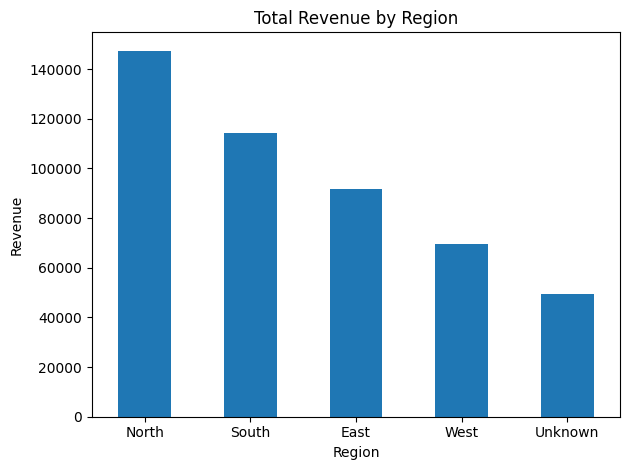

In [63]:
region_summary["TotalRevenue"].plot(
    kind="bar",
    title="Total Revenue by Region",
    xlabel="Region",
    ylabel="Revenue"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Monthly revenue trend

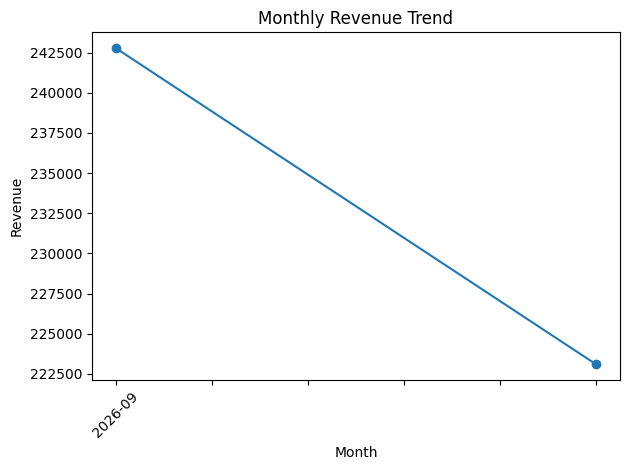

In [64]:
monthly_summary["TotalRevenue"].plot(
    kind="line",
    marker="o",
    title="Monthly Revenue Trend",
    xlabel="Month",
    ylabel="Revenue"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Revenue by product

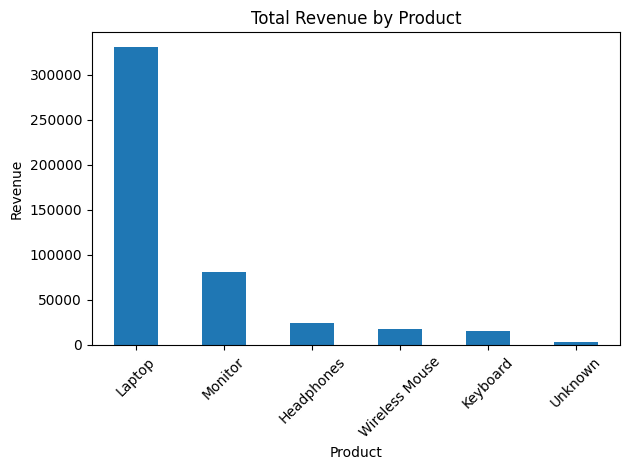

In [65]:
product_summary["TotalRevenue"].plot(
    kind="bar",
    title="Total Revenue by Product",
    xlabel="Product",
    ylabel="Revenue"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Counting values and inspecting unique categories

In [66]:
print("Orders by region:")
display(df_clean["Region"].value_counts())

print("Unique products:")
print(df_clean["Product"].unique())

print("Unique order IDs:", df_clean["OrderID"].nunique())

Orders by region:


,count
Region,
South,6
West,6
North,6
East,5
Unknown,1


Unique products:
['Laptop' 'Wireless Mouse' 'Keyboard' 'Monitor' 'Headphones' 'Unknown']
Unique order IDs: 24


stats n quantiles

In [67]:
print("Revenue statistics:")
display(df_clean["Revenue"].describe())

print("Median revenue:", df_clean["Revenue"].median())
print("75th percentile:", df_clean["Revenue"].quantile(0.75))
print("Maximum unit price:", df_clean["UnitPrice"].max())

Revenue statistics:


,Revenue
count,23.000000
mean,21306.630435
std,29934.839838
min,-27550.000000
25%,3581.250000
50%,6840.000000
75%,43410.000000
max,93600.000000


Median revenue: 6840.0
75th percentile: 43410.0
Maximum unit price: 52000


groupby

In [68]:
region_product_summary = (
    valid_sales.groupby(["Region", "Product"])
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalUnits=("Units", "sum")
    )
    .sort_values("TotalRevenue", ascending=False)
)

display(region_product_summary)

TotalRevenue  TotalUnits
Region  Product                                 
South   Laptop               93600.0         2.0
North   Laptop               91520.0         2.0
Unknown Laptop               49400.0         1.0
West    Laptop               49400.0         1.0
East    Laptop               46800.0         1.0
        Monitor              40600.0         3.0
North   Monitor              40020.0         3.0
South   Headphones           10880.0         4.0
North   Headphones            7680.0         3.0
West    Keyboard              6840.0         4.0
South   Wireless Mouse        6750.0        10.0
West    Headphones            6080.0         2.0
North   Keyboard              5400.0         3.0
East    Wireless Mouse        4500.0         6.0
West    Unknown               3600.0         2.0
        Wireless Mouse        3562.5         5.0
South   Keyboard              3240.0         2.0
North   Wireless Mouse        2850.0         4.0

using apply method to create a feature

In [69]:
df_clean["RevenueCategory"] = df_clean["Revenue"].apply(
    lambda x: "Unknown" if pd.isna(x)
    else "High" if x >= 1000
    else "Medium" if x >= 500
    else "Low"
)

display(df_clean[["OrderID", "Revenue", "RevenueCategory"]].head(10))

,OrderID,Revenue,RevenueCategory
0,EC1001,93600.0,High
1,EC1002,3562.5,High
2,EC1003,5400.0,High
3,EC1004,26100.0,High
4,EC1005,10880.0,High
5,EC1006,49400.0,High
6,EC1007,40020.0,High
7,EC1008,4500.0,High
8,EC1009,3240.0,High
9,EC1010,6080.0,High


correlation


In [70]:
correlation_matrix = df_clean[
    ["Units", "UnitPrice", "DiscountPct", "Revenue"]
].corr()

display(correlation_matrix)

,Units,UnitPrice,DiscountPct,Revenue
Units,1.000000,-0.442715,-0.059571,-0.141981
UnitPrice,-0.442715,1.000000,-0.096255,0.836359
DiscountPct,-0.059571,-0.096255,1.000000,-0.119761
Revenue,-0.141981,0.836359,-0.119761,1.000000


Standardizing region and product names

In [71]:
df_clean["Region"] = df_clean["Region"].astype("string").str.strip().str.title()
df_clean["Product"] = df_clean["Product"].astype("string").str.strip().str.title()

display(df_clean[["Region", "Product"]].head(10))

,Region,Product
0,South,Laptop
1,West,Wireless Mouse
2,North,Keyboard
3,East,Monitor
4,South,Headphones
5,West,Laptop
6,North,Monitor
7,East,Wireless Mouse
8,South,Keyboard
9,West,Headphones


Detecting revenue outliers using the IQR method

In [72]:
valid_revenue = valid_sales["Revenue"].dropna()

Q1 = valid_revenue.quantile(0.25)
Q3 = valid_revenue.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = valid_sales[
    (valid_sales["Revenue"] < lower_bound)
    | (valid_sales["Revenue"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Revenue outliers:", len(outliers))

display(outliers[["OrderID", "Product", "Revenue"]])


Lower bound: -52740.0
Upper bound: 101100.0
Revenue outliers: 0


,OrderID,Product,Revenue


box plot

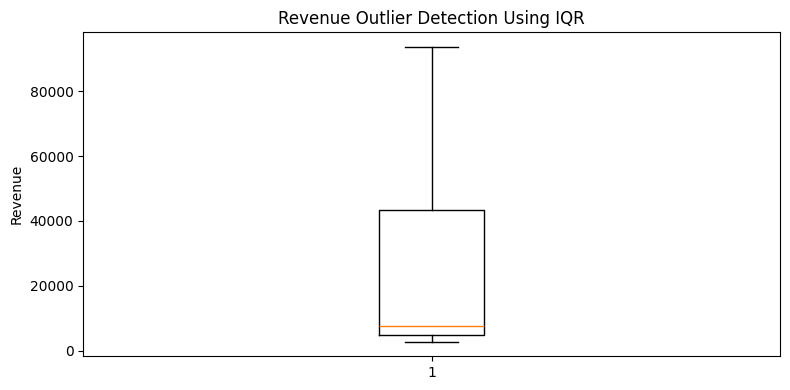

In [73]:
plt.figure(figsize=(8, 4))
plt.boxplot(valid_revenue)
plt.title("Revenue Outlier Detection Using IQR")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

final results

In [74]:
print("Final dataset shape:", df_clean.shape)
print("\nMissing values:")
display(df_clean.isna().sum())

print("\nExact duplicate rows:", df_clean.duplicated().sum())
print("Duplicate OrderIDs:", df_clean["OrderID"].duplicated().sum())
print("Invalid dates:", df_clean["Date"].isna().sum())

print("Invalid quantities:", (df_clean["Units"].notna() & (df_clean["Units"] <= 0)).sum())
print("Negative prices:", (df_clean["UnitPrice"].notna() & (df_clean["UnitPrice"] < 0)).sum())

print("\nFinal data types:")
df_clean.info()

Final dataset shape: (24, 13)

Missing values:


,0
OrderID,0
Date,1
Region,0
Product,0
Units,1
UnitPrice,0
DiscountPct,0
Year,1
MonthNumber,1
Day,1



Exact duplicate rows: 0
Duplicate OrderIDs: 0
Invalid dates: 1
Invalid quantities: 1
Negative prices: 1

Final data types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          24 non-null     object        
 1   Date             23 non-null     datetime64[ns]
 2   Region           24 non-null     string        
 3   Product          24 non-null     string        
 4   Units            23 non-null     float64       
 5   UnitPrice        24 non-null     int64         
 6   DiscountPct      24 non-null     float64       
 7   Year             23 non-null     float64       
 8   MonthNumber      23 non-null     float64       
 9   Day              23 non-null     float64       
 10  Month            23 non-null     object        
 11  Revenue          23 non-null     float64       
 12  RevenueCategory  24 non-nu

# **Business finding**

In [75]:
print("BUSINESS FINDINGS")
print("-" * 40)

print(
    f"Highest-revenue region: {region_summary['TotalRevenue'].idxmax()}"
)
print(
    f"Highest-revenue product: {product_summary['TotalRevenue'].idxmax()}"
)
print(
    f"Best sales month: {monthly_summary['TotalRevenue'].idxmax()}"
)
print(
    f"Total valid revenue: ₹{valid_sales['Revenue'].sum():,.2f}"
)
print(
    f"Number of exact duplicate rows removed: {df.shape[0] - df_clean.shape[0]}"
)

BUSINESS FINDINGS
----------------------------------------
Highest-revenue region: North
Highest-revenue product: Laptop
Best sales month: 2026-09
Total valid revenue: ₹472,722.50
Number of exact duplicate rows removed: 1
